In [2]:
# Import Pandas to load and inspect the dataset
import pandas as pd

# Load the cleaned dataset created in Task 1
file_path = r"C:\Users\ASUS\Downloads\swiggy_cleaned.csv"
df = pd.read_csv(file_path)

# Display the first five rows
display(df.head())

,restaurant_name,cuisine,rating,number_of_ratings,average_price,number_of_offers,offer_name,area,pure_veg,location
0,La Pino'Z Pizza,"Pizzas, Pastas",4.0,10.0,250,2,FLAT DEAL\nFLAT ₹125 OFF\nUSE FLAT125ABOVE ₹69...,LALA LAJPAT RAI MARKET,No,Abohar
1,The Second Wife,"Indian, North Indian",3.6,50.0,250,2,"30% OFF UPTO ₹75\nUSE TRYNEWABOVE ₹149, FLAT ₹...",Central Abohar,No,Abohar
2,Tasty Bites,"Italian, Beverages",3.8,10.0,200,1,FLAT ₹120 OFF\nUSE AXIS120ABOVE ₹500,Central Abohar,Yes,Abohar
3,Food Studio,"Pizzas, Burgers",3.5,8.0,49,5,"50% OFF UPTO ₹100\nUSE TRYNEWABOVE ₹129, FLAT ...",Central Abohar,Yes,Abohar
4,Roll Express,"Fast Food, Snacks",4.3,100.0,200,2,DEAL OF DAY\n10% OFF UPTO ₹40\nUSE STEALDEALAB...,Circular Road,No,Abohar


In [3]:

# Count how many rows have a missing rating
print("Missing ratings:", df["rating"].isna().sum())

# Count how many ratings are available for model training
print("Available ratings:", df["rating"].notna().sum())

Missing ratings: 33457
Available ratings: 105864


In [4]:
# Keep only rows where the restaurant rating is available
df_model = df.dropna(subset=["rating"]).copy()

# Check the dataset size after filtering
print("Dataset shape for modeling:", df_model.shape)

# Confirm that no target ratings are missing
print("Missing target values:", df_model["rating"].isna().sum())

# Display the rating distribution
display(df_model["rating"].describe())

Dataset shape for modeling: (105864, 10)
Missing target values: 0


count    105864.000000
mean          4.038306
std           0.495581
min           1.000000
25%           3.800000
50%           4.100000
75%           4.300000
max           5.000000
Name: rating, dtype: float64

In [5]:
# Select useful input features for predicting restaurant ratings
X = df_model[
    [
        "cuisine",
        "number_of_ratings",
        "average_price",
        "number_of_offers",
        "area",
        "pure_veg",
        "location"
    ]
].copy()

# Store the restaurant rating as the target variable
y = df_model["rating"].copy()

# Check the input features and target shape
print("Features shape:", X.shape)
print("Target shape:", y.shape)

# Check missing values in the selected features
display(X.isna().sum())

Features shape: (105864, 7)
Target shape: (105864,)


cuisine              0
number_of_ratings    0
average_price        0
number_of_offers     0
area                 0
pure_veg             0
location             0
dtype: int64

In [6]:
# Split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Use 80% of the data for training and 20% for testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the sizes of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)

Training features: (84691, 7)
Testing features: (21173, 7)
Training targets: (84691,)
Testing targets: (21173,)


In [7]:
# Import tools for preprocessing numerical and categorical features
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Identify categorical and numerical columns
categorical_features = [
    "cuisine",
    "area",
    "pure_veg",
    "location"
]

numerical_features = [
    "number_of_ratings",
    "average_price",
    "number_of_offers"
]

# Convert categorical values into numerical indicator columns
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [8]:
# Import Linear Regression
from sklearn.linear_model import LinearRegression

# Create a pipeline that preprocesses the data and trains the model
linear_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        ("model", LinearRegression())
    ]
)

# Train the model using the training dataset
linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [9]:
# Import evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict restaurant ratings for the unseen test data
y_pred_linear = linear_model.predict(X_test)

# Calculate the evaluation metrics
mae_linear = mean_absolute_error(y_test, y_pred_linear)
rmse_linear = np.sqrt(mean_squared_error(y_test, y_pred_linear))
r2_linear = r2_score(y_test, y_pred_linear)

# Display the results
print("Linear Regression Results")
print("-------------------------")
print("MAE:", round(mae_linear, 4))
print("RMSE:", round(rmse_linear, 4))
print("R² Score:", round(r2_linear, 4))

Linear Regression Results
-------------------------
MAE: 0.3447
RMSE: 0.4725
R² Score: 0.0903


In [10]:
# Import Random Forest
from sklearn.ensemble import RandomForestRegressor

# Select a smaller sample to reduce training time
X_train_small = X_train.sample(
    n=min(25000, len(X_train)),
    random_state=42
)

# Select matching target values for the sampled rows
y_train_small = y_train.loc[X_train_small.index]

# Build a smaller Random Forest pipeline
rf_model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=15,
                max_depth=10,
                min_samples_leaf=10,
                random_state=42,
                n_jobs=2
            )
        )
    ]
)

# Train on the smaller sample
rf_model.fit(X_train_small, y_train_small)

print("Lightweight Random Forest model trained successfully!")

Lightweight Random Forest model trained successfully!


In [11]:
# Import the evaluation metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predict ratings for the same test dataset
y_pred_rf = rf_model.predict(X_test)

# Calculate evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

# Display Random Forest results
print("Random Forest Results")
print("---------------------")
print("MAE:", round(mae_rf, 4))
print("RMSE:", round(rmse_rf, 4))
print("R² Score:", round(r2_rf, 4))

Random Forest Results
---------------------
MAE: 0.3463
RMSE: 0.4757
R² Score: 0.0776


In [12]:
# Create a table to compare both trained models
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae_linear, mae_rf],
    "RMSE": [rmse_linear, rmse_rf],
    "R2 Score": [r2_linear, r2_rf]
})

# Display the comparison with rounded values
display(results.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.3447,0.4725,0.0903
1,Random Forest,0.3463,0.4757,0.0776


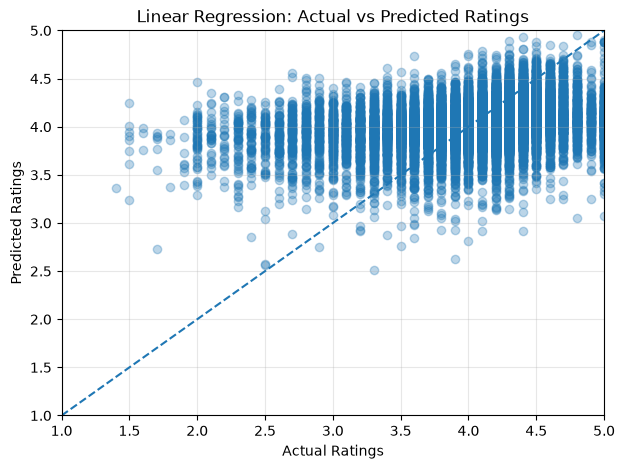

In [13]:
# Import Matplotlib for visualization
import matplotlib.pyplot as plt

# Compare actual ratings with Linear Regression predictions
plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred_linear, alpha=0.3)

# Add a reference line for perfect predictions
plt.plot([1, 5], [1, 5], linestyle="--")

plt.xlabel("Actual Ratings")
plt.ylabel("Predicted Ratings")
plt.title("Linear Regression: Actual vs Predicted Ratings")
plt.xlim(1, 5)
plt.ylim(1, 5)
plt.grid(True, alpha=0.3)
plt.show()

## Final Conclusion

In this task, two machine learning regression models were trained and evaluated to predict restaurant ratings using the Swiggy dataset.

Linear Regression achieved an MAE of **0.3447**, RMSE of **0.4725**, and R² score of **0.0903**. The lightweight Random Forest model achieved an MAE of **0.3463**, RMSE of **0.4757**, and R² score of **0.0776**.

Based on these results, Linear Regression performed slightly better on the test dataset. However, both models showed limited predictive performance, suggesting that the selected features may not fully explain restaurant ratings. The comparison also has a limitation because Random Forest was trained on a smaller sample than Linear Regression.

This task provided practical experience in data preprocessing, model training, regression evaluation metrics, visualization, and model comparison. Further improvements could include feature engineering, testing additional regression models, and training both models on the same dataset for a fair comparison.